In [22]:
import backtrader as bt
import datetime
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
%matplotlib inline

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Starting Portfolio Value: 10000.00
2018-02-12, BUY CREATED --- Size: 123, Cash: 10000.00, Open: 81.10188200739728, Close:                         81.45831298828125
2018-02-12, BUY EXECUTED --- Price: 81.10, Cost: 9975.53,                         Commission: 9.98
2018-02-12, OPERATION RESULT --- Gross: 0.00, Net: -9.98
2018-04-19, SELL CREATED --- Size: 123
2018-04-19, SELL EXECUTED --- Price:                     88.55, Cost: 9975.53,                     Commission: 10.89
2018-06-29, BUY CREATED --- Size: 119, Cash: 10895.64, Open: 91.23326754466933, Close:                         90.93816375732422
2018-06-29, BUY EXECUTED --- Price: 91.23, Cost: 10856.76,                         Commission: 10.86
2018-06-29, OPERATION RESULT --- Gross: 0.00, Net: -10.86
2018-07-17, SELL CREATED --- Size: 119
2018-07-17, SELL EXECUTED --- Price:                     96.47, Cost: 10856.76,                     Commission: 11.48
2018-10-15, BUY CREATED --- Size: 114, Cash: 11496.64, Open: 100.82333175331259

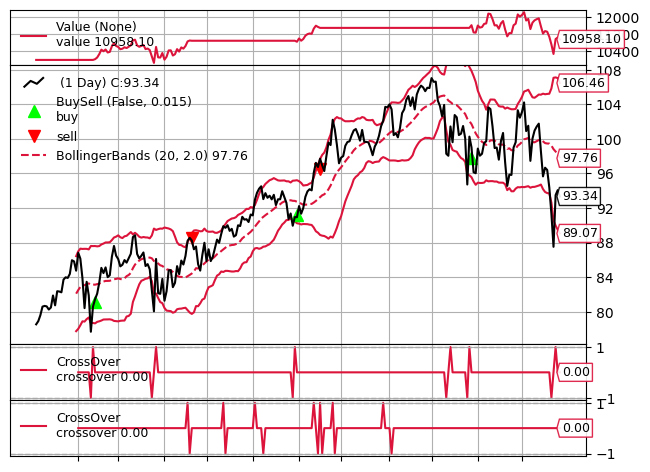

[[<Figure size 640x480 with 4 Axes>]]

In [24]:
class BBand_Strategy(bt.Strategy):
    params = (('period', 20),
    ('devfactor', 2.0),)
   
    def __init__(self):
        # keep track of close price in the series
        self.data_close = self.datas[0].close
        self.data_open = self.datas[0].open
        # keep track of pending orders/buy price/buy commission
        self.order = None
        self.price = None
        self.comm = None
        # add Bollinger Bands indicator and track the buy/sell signals
        self.b_band = bt.ind.BollingerBands(self.datas[0],period=self.p.period, devfactor=self.p.devfactor)
        self.buy_signal = bt.ind.CrossOver(self.datas[0], self.b_band.lines.bot)
        self.sell_signal = bt.ind.CrossOver(self.datas[0], self.b_band.lines.top)
    
    def log(self, txt):
        dt = self.datas[0].datetime.date(0).isoformat()
        print(f'{dt}, {txt}')
        
    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return
        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED --- Price: {order.executed.price:.2f}, Cost: {order.executed.value:.2f}, \
                        Commission: {order.executed.comm:.2f}'
                        )
                self.price = order.executed.price
                self.comm = order.executed.comm
            else:
                self.log(
                    f'SELL EXECUTED --- Price: \
                    {order.executed.price:.2f}, Cost: {order.executed.value:.2f}, \
                    Commission: {order.executed.comm:.2f}'
                    )
        elif order.status in [order.Canceled, order.Margin,order.Rejected]:
            self.log('Order Failed')
            self.order = None
                
    def notify_trade(self, trade):
        if not trade.isclosed:
            return self.log(f'OPERATION RESULT --- Gross: {trade.pnl:.2f}, Net: {trade.pnlcomm:.2f}')
        
    def next_open(self):
        if not self.position:
            if self.buy_signal > 0:
                size = int(self.broker.getcash() / self.datas[0].open)
                self.log(f"""BUY CREATED --- Size: {size}, Cash: {self.broker.getcash():.2f}, Open: {self.data_open[0]}, Close: \
                        {self.data_close[0]}""") 
                self.buy(size=size)
        else:
            if self.sell_signal < 0:
                self.log(f'SELL CREATED --- Size: {self.position.size}') 
                self.sell(size=self.position.size)



data = yf.download('MSFT', start='2018-01-01', end='2018-12-31')
data.columns = data.columns.droplevel(level=1)
# Convert for Backtrader
datafeed = bt.feeds.PandasData(dataname=data)


cerebro = bt.Cerebro(stdstats = False, cheat_on_open=True)
cerebro.addstrategy(BBand_Strategy)
cerebro.adddata(datafeed)
cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.001)
cerebro.addobserver(bt.observers.BuySell)
cerebro.addobserver(bt.observers.Value)
cerebro.addanalyzer(bt.analyzers.Returns, _name='returns')
cerebro.addanalyzer(bt.analyzers.TimeReturn, _name='time_return')


print('Starting Portfolio Value: %.2f' % cerebro.broker.getvalue())
backtest_result = cerebro.run()
print('Final Portfolio Value: %.2f' % cerebro.broker.getvalue())

cerebro.plot(iplot=False, volume=False)


In [3]:
print(backtest_result[0].analyzers.returns.get_analysis())

OrderedDict({'rtot': 0.0914942399828026, 'ravg': 0.0003659769599312104, 'rnorm': 0.09661284116781321, 'rnorm100': 9.66128411678132})


<Axes: title={'center': 'Portfolio returns'}, xlabel='report_date'>

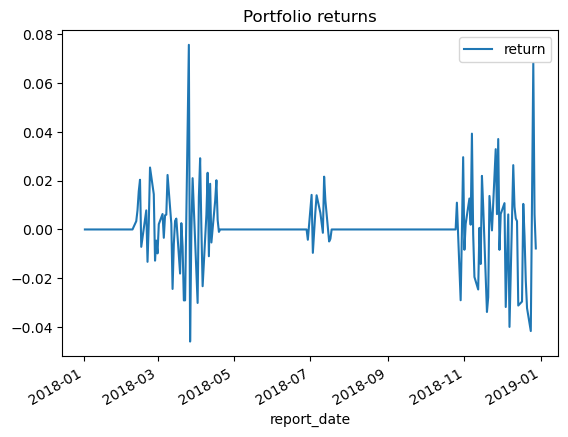

In [23]:
returns_dict = backtest_result[0].analyzers.time_return.get_analysis()
returns_df = pd.DataFrame(list(returns_dict.items()), columns = ['report_date', 'return']).set_index('report_date')
returns_df.plot(title='Portfolio returns')